# 03 · Análisis exploratorio

**Proyecto:** videos en tendencia de YouTube en Estados Unidos
**Metodología:** CRISP-DM, etapa 2 (comprensión de los datos), sobre el dataset ya preparado

Este notebook responde con análisis descriptivo dos de las preguntas del enunciado y prepara el terreno para los modelos:

1. ¿Qué categorías reciben más vistas y likes?
2. ¿Influye la fecha en que se publica el video?
3. ¿Qué otros factores se asocian con el desempeño (canal, título, etiquetas)?

Todo se analiza **a nivel de video** (6.347 videos), con las métricas al último día en tendencia. Se usa la **mediana** porque unos pocos videos virales distorsionan el promedio.

In [1]:
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy import stats

sys.path.append(str(Path.cwd().parent))
from src import prep
from src.data import FIGURES_DIR, PROCESSED_DIR
from src.viz import BLUE, COMPACT, INK_SECONDARY, PALETTE, set_style

set_style()
pd.set_option("display.float_format", "{:,.3f}".format)

videos = pd.read_parquet(PROCESSED_DIR / "videos.parquet")
daily = pd.read_parquet(PROCESSED_DIR / "daily.parquet")
print(f"{len(videos):,} videos · mediana de vistas {videos['views_last'].median():,.0f} · "
      f"mediana de likes {videos['likes_last'].median():,.0f}")


def eta_squared(df, group, target="log_views_last"):
    """Proporción de la variación de `target` que se explica por pertenecer a un grupo."""
    g = df.groupby(group, observed=True)[target]
    mean = df[target].mean()
    return (g.count() * (g.mean() - mean) ** 2).sum() / ((df[target] - mean) ** 2).sum()

6,347 videos · mediana de vistas 516,574 · mediana de likes 12,009


## 1. Categorías: ¿cuáles reciben más vistas y likes?

Hay tres formas de leer "la mejor categoría", y no coinciden:

- **Presencia:** cuántos videos de la categoría llegan a tendencia.
- **Alcance:** cuántas vistas y likes consigue un video típico.
- **Interacción:** qué proporción de quienes ven el video le da like.

In [2]:
by_cat = videos.groupby("category").agg(
    videos=("video_id", "count"),
    canales=("channel_title", "nunique"),
    vistas_mediana=("views_last", "median"),
    likes_mediana=("likes_last", "median"),
    like_rate=("like_rate", "median"),
    comment_rate=("comment_rate", "median"),
    dislike_share=("dislike_share", "median"),
    vistas_total=("views_last", "sum"),
)
by_cat["% videos"] = by_cat["videos"] / by_cat["videos"].sum() * 100
by_cat["% vistas"] = by_cat["vistas_total"] / by_cat["vistas_total"].sum() * 100
by_cat = by_cat.drop(columns="vistas_total").sort_values("vistas_mediana", ascending=False)

by_cat.style.format({
    "vistas_mediana": "{:,.0f}", "likes_mediana": "{:,.0f}", "like_rate": "{:.1%}",
    "comment_rate": "{:.2%}", "dislike_share": "{:.1%}", "% videos": "{:.1f}", "% vistas": "{:.1f}",
})

,videos,canales,vistas_mediana,likes_mediana,like_rate,comment_rate,dislike_share,% videos,% vistas
category,,,,,,,,,
Gaming,103,65,"1,316,002","36,922",2.8%,0.52%,3.7%,1.6,1.9
Music,799,438,"1,096,158","40,469",3.5%,0.24%,2.3%,12.6,38.7
Film & Animation,317,139,"910,966","12,584",2.1%,0.25%,4.3%,5.0,6.5
Comedy,547,144,"788,112","22,884",3.1%,0.24%,3.2%,8.6,6.3
Shows,4,2,"765,522","13,675",2.0%,0.26%,3.8%,0.1,0.0
Entertainment,1617,474,"606,048","11,770",2.0%,0.22%,4.0%,25.5,22.7
Science & Technology,380,165,"431,058","11,571",2.5%,0.30%,3.5%,6.0,3.4
Howto & Style,595,190,"422,918","15,910",4.0%,0.36%,2.4%,9.4,4.5
Pets & Animals,138,55,"413,038","11,601",3.1%,0.28%,1.8%,2.2,0.8


Las categorías con menos de 20 videos (Shows, Nonprofits & Activism) se dejan fuera de los gráficos: con tan pocos casos su mediana no es confiable.

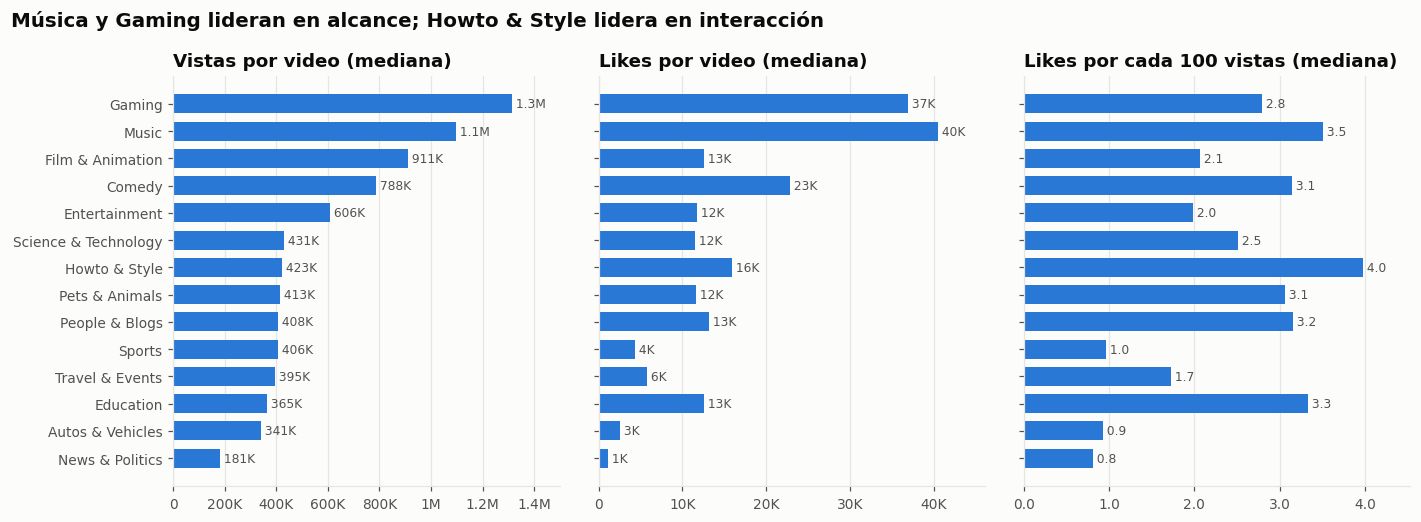

In [3]:
main = by_cat[by_cat["videos"] >= 20].sort_values("vistas_mediana")

fig, axes = plt.subplots(1, 3, figsize=(13, 4.8), sharey=True)
panels = [
    ("vistas_mediana", "Vistas por video (mediana)", COMPACT),
    ("likes_mediana", "Likes por video (mediana)", COMPACT),
    ("like_rate", "Likes por cada 100 vistas (mediana)", lambda x, _: f"{x * 100:.1f}"),
]
for ax, (col, title, fmt) in zip(axes, panels):
    ax.barh(main.index, main[col], color=BLUE, height=0.7)
    ax.set_title(title)
    ax.xaxis.set_major_formatter(fmt)
    ax.grid(axis="x")
    ax.grid(axis="y", visible=False)
    for y, value in enumerate(main[col]):
        ax.text(value, y, " " + fmt(value, None), va="center", fontsize=8, color=INK_SECONDARY)
    ax.margins(x=0.14)
fig.suptitle("Música y Gaming lideran en alcance; Howto & Style lidera en interacción",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_categorias.png")
plt.show()

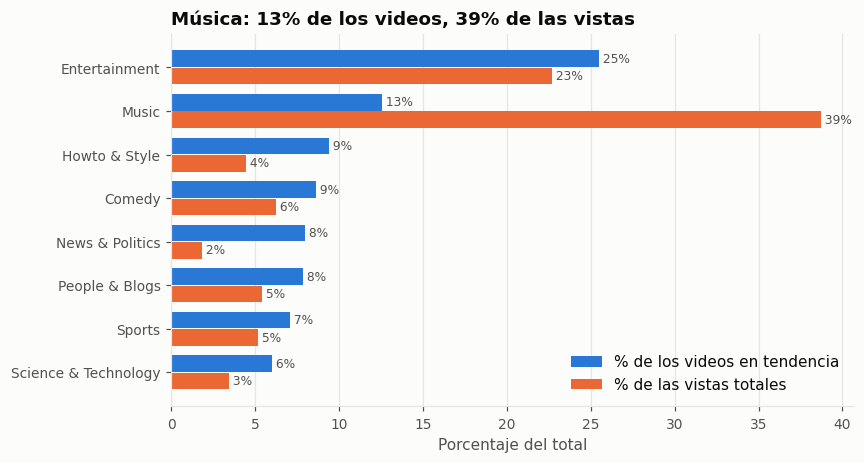

In [4]:
top = by_cat.sort_values("% videos", ascending=False).head(8).iloc[::-1]
y = np.arange(len(top))

fig, ax = plt.subplots(figsize=(8, 4.4))
ax.barh(y + 0.2, top["% videos"], height=0.38, color=PALETTE[0], label="% de los videos en tendencia")
ax.barh(y - 0.2, top["% vistas"], height=0.38, color=PALETTE[1], label="% de las vistas totales")
for yy, (a, b) in enumerate(zip(top["% videos"], top["% vistas"])):
    ax.text(a, yy + 0.2, f" {a:.0f}%", va="center", fontsize=8, color=INK_SECONDARY)
    ax.text(b, yy - 0.2, f" {b:.0f}%", va="center", fontsize=8, color=INK_SECONDARY)
ax.set_yticks(y, top.index)
ax.set_title("Música: 13% de los videos, 39% de las vistas")
ax.set_xlabel("Porcentaje del total")
ax.grid(axis="x"); ax.grid(axis="y", visible=False)
ax.legend(loc="lower right")
fig.savefig(FIGURES_DIR / "03_presencia_vs_vistas.png")
plt.show()

In [5]:
groups = [g["log_views_last"].to_numpy() for _, g in videos.groupby("category")]
kw = stats.kruskal(*groups)
print(f"Kruskal-Wallis entre categorías: H = {kw.statistic:.0f}, p = {kw.pvalue:.1e}")
print(f"La categoría explica el {eta_squared(videos, 'category'):.1%} de la variación de las vistas (en logaritmo).")

Kruskal-Wallis entre categorías: H = 481, p = 5.9e-93
La categoría explica el 8.2% de la variación de las vistas (en logaritmo).


**Lectura:**

- **Entertainment es la categoría con más presencia** (25% de los videos en tendencia), pero su video típico tiene un alcance medio (606 mil vistas).
- **Música y Gaming tienen el mayor alcance por video**: más de un millón de vistas y cerca de 40 mil likes de mediana, tres veces los likes del video típico. Música concentra el 39% de todas las vistas con solo el 13% de los videos.
- **Howto & Style tiene la mayor interacción**: 4 likes por cada 100 vistas, el doble que Entertainment. Su audiencia es más pequeña pero responde más.
- **News & Politics y Sports generan poca interacción positiva** (cerca de 1 like por cada 100 vistas). En News & Politics, además, el 16% de las valoraciones son negativas, frente al 2–5% del resto: es contenido polémico, un riesgo para una marca.
- Las diferencias entre categorías son estadísticamente claras, pero la categoría explica menos del 9% de la variación de las vistas. **Dentro de una misma categoría hay videos de todos los tamaños**: elegir bien la categoría ayuda, no garantiza.

## 2. Un hallazgo no previsto: la lista de tendencias cambia en marzo de 2018

Antes de analizar la fecha de publicación conviene mirar cómo evoluciona el dataset mes a mes.

In [6]:
monthly = videos.assign(mes=videos["first_trending_date"].dt.to_period("M")).groupby("mes").agg(
    videos_nuevos=("video_id", "count"),
    vistas_mediana=("views_last", "median"),
    dias_en_tendencia=("days_trending", "mean"),
)
monthly.index = monthly.index.strftime("%b %y")
monthly

,videos_nuevos,vistas_mediana,dias_en_tendencia
mes,,,
Nov 17,903,"295,048.000",4.315
Dec 17,1215,"295,841.000",5.291
Jan 18,1237,"301,706.000",4.352
Feb 18,1059,"372,894.000",5.822
Mar 18,692,"800,737.500",9.055
Apr 18,533,"1,188,770.000",9.445
May 18,542,"1,463,924.000",12.290
Jun 18,166,"1,707,050.500",6.247


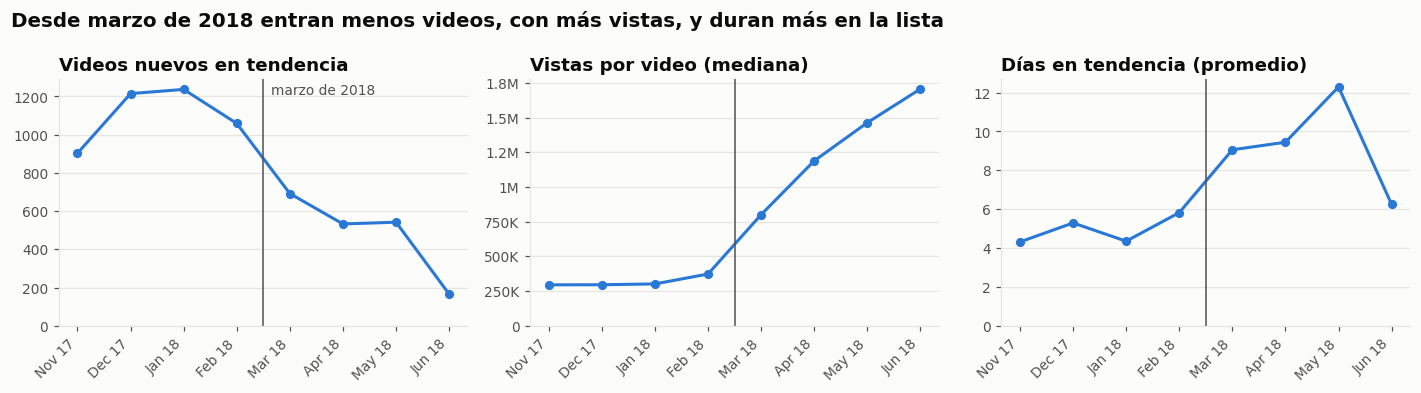

In [7]:
fig, axes = plt.subplots(1, 3, figsize=(13, 3.6))
panels = [
    ("videos_nuevos", "Videos nuevos en tendencia", None),
    ("vistas_mediana", "Vistas por video (mediana)", COMPACT),
    ("dias_en_tendencia", "Días en tendencia (promedio)", None),
]
x = np.arange(len(monthly))
for ax, (col, title, fmt) in zip(axes, panels):
    ax.plot(x, monthly[col], color=BLUE, marker="o", markersize=5)
    ax.axvline(3.5, color=INK_SECONDARY, linewidth=1)
    ax.set_xticks(x, monthly.index, rotation=45, ha="right")
    ax.set_title(title)
    ax.set_ylim(0)
    if fmt:
        ax.yaxis.set_major_formatter(fmt)
axes[0].annotate("marzo de 2018", xy=(3.5, axes[0].get_ylim()[1]), xytext=(5, -10),
                 textcoords="offset points", fontsize=9, color=INK_SECONDARY)
fig.suptitle("Desde marzo de 2018 entran menos videos, con más vistas, y duran más en la lista",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_cambio_marzo_2018.png")
plt.show()

In [8]:
videos = prep.add_period(videos)

periods = videos.groupby("period", observed=True).agg(
    videos=("video_id", "count"),
    canales=("channel_title", "nunique"),
    vistas_mediana=("views_last", "median"),
    dias_en_tendencia=("days_trending", "mean"),
    dias_hasta_tendencia=("days_to_trending", "median"),
    like_rate=("like_rate", "median"),
)
display(periods)
print(f"El periodo explica el {eta_squared(videos, 'period'):.1%} de la variación de las vistas.")

,videos,canales,vistas_mediana,dias_en_tendencia,dias_hasta_tendencia,like_rate
period,,,,,,
Nov 2017 – Feb 2018,4414,1885,"317,094.000",4.956,2.000,0.024
Mar – Jun 2018,1933,752,"1,142,433.000",9.828,2.000,0.024


El periodo explica el 14.6% de la variación de las vistas.


Entre noviembre y febrero entran unos 1.100 videos nuevos por mes, con unas 320 mil vistas de mediana y 5 días en la lista. Desde marzo entran cerca de la mitad, con más de un millón de vistas y casi 10 días en la lista. Junio solo tiene 14 días de datos, por eso sus videos nuevos y sus días en tendencia aparecen más bajos. La lista sigue teniendo 200 videos por día: como cada video permanece más tiempo, hay menos cupo para videos nuevos.

El dataset no dice por qué ocurre. Lo más probable es un cambio en la forma en que YouTube arma la lista, no un cambio en el gusto de la audiencia: la tasa de likes y los días que tarda un video en llegar son iguales en ambos periodos.

**Consecuencias para el análisis:**

- El "mes" no se puede leer como estacionalidad. La diferencia entre diciembre y mayo refleja este cambio, no la época del año.
- El periodo explica más variación de las vistas (15%) que la categoría (8%). Toda comparación debe hacerse **dentro de cada periodo**, y los modelos deben incluirlo.
- La barra para entrar a tendencia subió. Para la empresa, la referencia válida de hoy es el periodo más reciente.

In [9]:
cat_period = videos.pivot_table(index="category", columns="period", values="views_last",
                                aggfunc="median", observed=True)
cat_period["posición antes"] = cat_period[prep.PERIODS[0]].rank(ascending=False).astype(int)
cat_period["posición después"] = cat_period[prep.PERIODS[1]].rank(ascending=False).astype(int)
counts = videos["category"].value_counts()
cat_period = cat_period[counts.reindex(cat_period.index) >= 20].sort_values("posición después")

rho = stats.spearmanr(cat_period[prep.PERIODS[0]], cat_period[prep.PERIODS[1]])[0]
print(f"Correlación entre el orden de las categorías en ambos periodos: {rho:.2f}")
cat_period.style.format({p: "{:,.0f}" for p in prep.PERIODS})

Correlación entre el orden de las categorías en ambos periodos: 0.66


period,Nov 2017 – Feb 2018,Mar – Jun 2018,posición antes,posición después
category,,,,
Music,"617,406","3,570,975",1,1
Gaming,"387,223","2,577,609",3,2
Film & Animation,"349,743","1,879,678",5,3
Comedy,"554,706","1,352,780",2,5
Entertainment,"368,586","1,184,957",4,6
People & Blogs,"251,710","1,156,041",13,7
Autos & Vehicles,"275,180","1,052,662",9,8
Science & Technology,"309,971","965,264",7,9
Travel & Events,"270,360","814,243",10,10


El orden se mantiene en lo esencial: Música, Gaming, Film & Animation y Comedy están entre las cinco primeras en ambos periodos, y Sports y News & Politics en la parte baja. Los cambios más grandes son Education, que baja del puesto 6 al 15, y People & Blogs, que sube del 13 al 7. La conclusión de la sección 1 sobre qué categorías tienen más alcance no depende del cambio de marzo.

## 3. ¿Influye el momento de publicación?

Se excluyen los 101 videos antiguos que resurgieron, porque su fecha de publicación no tiene relación con su llegada a tendencia. Las horas están en hora del este de Estados Unidos.

### 3.1 Cuándo se publican los videos que llegan a tendencia

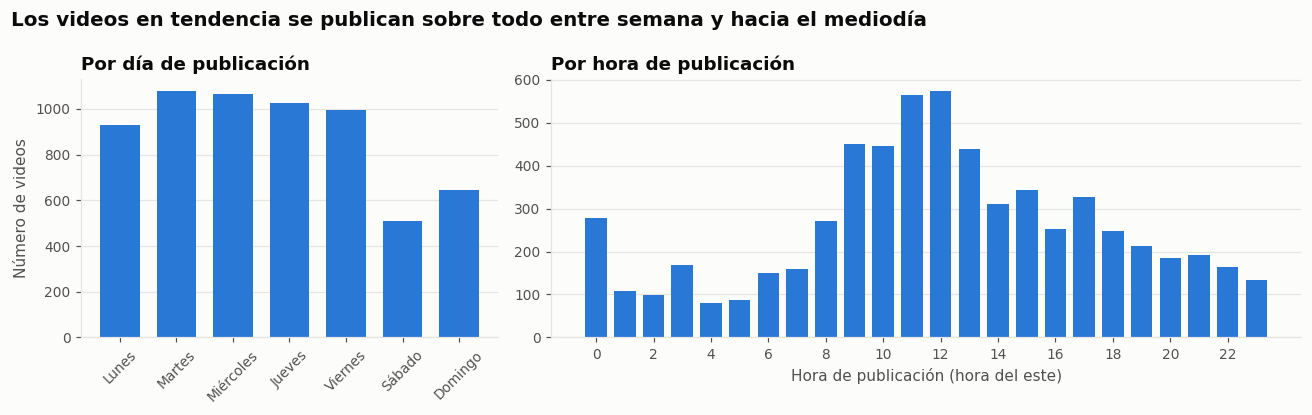

Publicados entre lunes y viernes: 81% · publicados entre 9 a. m. y 1 p. m.: 40%


In [10]:
recent = videos[~videos["is_old_video"]].copy()

by_day = recent.groupby("publish_day_name", observed=True).agg(
    videos=("video_id", "count"), vistas_mediana=("views_last", "median"),
    like_rate=("like_rate", "median"),
)
by_hour = recent.groupby("publish_hour").agg(
    videos=("video_id", "count"), vistas_mediana=("views_last", "median"),
)

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8), gridspec_kw={"width_ratios": [1, 1.8]})
axes[0].bar(by_day.index, by_day["videos"], color=BLUE, width=0.7)
axes[0].set_title("Por día de publicación")
axes[0].tick_params(axis="x", rotation=45)
axes[0].set_ylabel("Número de videos")

axes[1].bar(by_hour.index, by_hour["videos"], color=BLUE, width=0.75)
axes[1].set_title("Por hora de publicación")
axes[1].set_xlabel("Hora de publicación (hora del este)")
axes[1].set_xticks(range(0, 24, 2))
fig.suptitle("Los videos en tendencia se publican sobre todo entre semana y hacia el mediodía",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_cuando_se_publica.png")
plt.show()

weekday_share = 1 - recent["publish_is_weekend"].mean()
midday_share = recent["publish_hour"].between(9, 13).mean()
print(f"Publicados entre lunes y viernes: {weekday_share:.0%} · publicados entre 9 a. m. y 1 p. m.: {midday_share:.0%}")

El 81% de los videos en tendencia se publicó entre semana, y el 40% entre las 9 a. m. y la 1 p. m. Esto describe **cuándo publican los canales que llegan a tendencia**; no prueba que publicar a esa hora aumente la probabilidad de llegar, porque no hay datos de los videos que no llegaron.

### 3.2 ¿Los videos publicados en ciertos días u horas consiguen más vistas?

Para aislar el efecto del momento de publicación, las vistas de cada video se comparan con la mediana de su misma categoría y periodo. Un valor de 1,10 significa "10% más vistas que un video comparable".

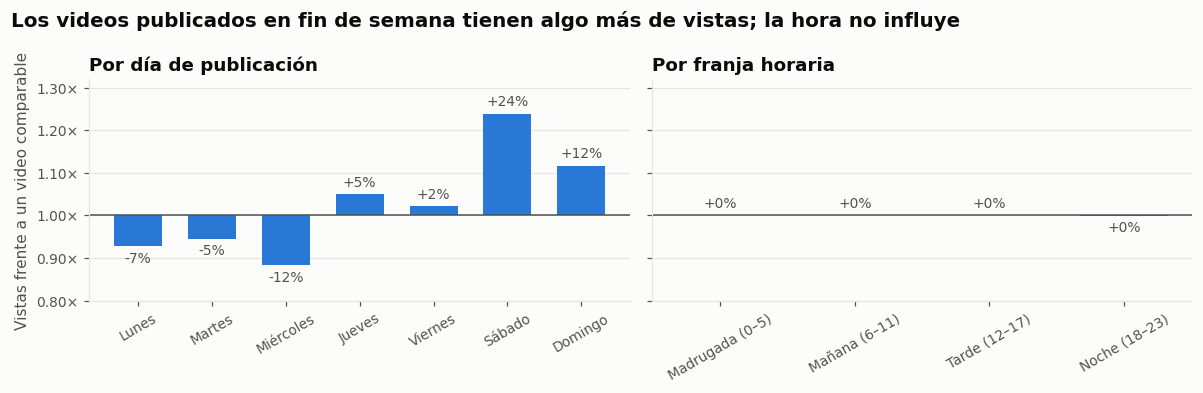

In [11]:
baseline = recent.groupby(["category", "period"], observed=True)["log_views_last"].transform("median")
recent["rel_log_views"] = recent["log_views_last"] - baseline

recent["franja"] = pd.cut(recent["publish_hour"], [-1, 5, 11, 17, 23],
                          labels=["Madrugada (0–5)", "Mañana (6–11)", "Tarde (12–17)", "Noche (18–23)"])

rel_day = np.exp(recent.groupby("publish_day_name", observed=True)["rel_log_views"].median())
rel_slot = np.exp(recent.groupby("franja", observed=True)["rel_log_views"].median())

fig, axes = plt.subplots(1, 2, figsize=(11, 3.6), sharey=True)
for ax, series, title in [(axes[0], rel_day, "Por día de publicación"),
                          (axes[1], rel_slot, "Por franja horaria")]:
    ax.bar(series.index.astype(str), series.values - 1, bottom=1, color=BLUE, width=0.65)
    ax.axhline(1, color=INK_SECONDARY, linewidth=1)
    for i, value in enumerate(series.values):
        ax.text(i, value + (0.012 if value >= 1 else -0.012), f"{round(value - 1, 2) + 0:+.0%}", ha="center",
                va="bottom" if value >= 1 else "top", fontsize=9, color=INK_SECONDARY)
    ax.set_title(title)
    ax.tick_params(axis="x", rotation=30)
axes[0].set_ylabel("Vistas frente a un video comparable")
axes[0].yaxis.set_major_formatter(lambda x, _: f"{x:.2f}×")
axes[0].set_ylim(0.8, 1.32)
fig.suptitle("Los videos publicados en fin de semana tienen algo más de vistas; la hora no influye",
             x=0.01, ha="left", fontsize=13, fontweight="bold")
fig.tight_layout()
fig.savefig(FIGURES_DIR / "03_efecto_momento_publicacion.png")
plt.show()

In [12]:
tests = pd.DataFrame(
    {
        "p (Kruskal-Wallis)": {
            "Día de la semana": stats.kruskal(*[g["rel_log_views"] for _, g in recent.groupby("publish_dow")]).pvalue,
            "Franja horaria": stats.kruskal(*[g["rel_log_views"] for _, g in recent.groupby("franja", observed=True)]).pvalue,
        },
        "% de variación explicada": {
            "Día de la semana": eta_squared(recent, "publish_dow", "rel_log_views") * 100,
            "Franja horaria": eta_squared(recent, "franja", "rel_log_views") * 100,
        },
    }
)
display(tests.style.format({"p (Kruskal-Wallis)": "{:.1e}", "% de variación explicada": "{:.2f}"}))

weekend = recent.groupby("publish_is_weekend").agg(
    videos=("video_id", "count"),
    vistas_relativas=("rel_log_views", lambda s: np.exp(s.median())),
    like_rate=("like_rate", "median"),
).rename(index={False: "Lunes a viernes", True: "Fin de semana"})
weekend

,p (Kruskal-Wallis),% de variación explicada
Día de la semana,3.4e-06,0.59
Franja horaria,5.6e-01,0.05


,videos,vistas_relativas,like_rate
publish_is_weekend,,,
Lunes a viernes,5090,0.971,0.025
Fin de semana,1156,1.159,0.022


**Lectura:**

- **Día de la semana:** los videos publicados en sábado y domingo tienen entre 12% y 24% más vistas que un video comparable, y los del miércoles un 12% menos. La diferencia es estadísticamente significativa, pero explica menos del 1% de la variación: es un efecto real y pequeño.
- **Una explicación posible** es la competencia: en fin de semana se publica menos de la mitad de videos por día que entre semana, así que cada uno disputa la atención con menos rivales. Los datos no permiten confirmarlo.
- **Hora:** una vez descontados categoría y periodo, no hay diferencia entre franjas horarias.
- **Estacionalidad anual:** no se puede evaluar con siete meses de datos, y el cambio de marzo de 2018 impide comparar meses entre sí.

**Respuesta a la pregunta:** el momento de publicación influye poco. Publicar en fin de semana da una ventaja pequeña; la hora no importa. Qué se publica y quién lo publica pesa mucho más que cuándo.

## 4. El canal: quién publica

En el notebook 02 se vio que el 10% de los canales aporta la mitad de los videos en tendencia.

In [13]:
top_channels = videos.groupby("channel_title").agg(
    videos=("video_id", "count"),
    categoria=("category", lambda s: s.mode()[0]),
    vistas_mediana=("views_last", "median"),
    like_rate=("like_rate", "median"),
).sort_values("videos", ascending=False).head(12)
top_channels.style.format({"vistas_mediana": "{:,.0f}", "like_rate": "{:.1%}"})

,videos,categoria,vistas_mediana,like_rate
channel_title,,,,
ESPN,84,Sports,"506,190",0.8%
TheEllenShow,74,Entertainment,"883,050",1.9%
The Tonight Show Starring Jimmy Fallon,72,Comedy,"590,906",1.8%
Jimmy Kimmel Live,70,Entertainment,"874,775",1.6%
The Late Show with Stephen Colbert,58,Entertainment,"577,808",1.2%
Netflix,58,Entertainment,"433,454",1.8%
NBA,55,Sports,"293,295",1.3%
CNN,52,News & Politics,"327,963",0.8%
Vox,47,News & Politics,"655,073",2.7%


In [14]:
videos["canal_tramo"] = pd.cut(videos["channel_videos"], [0, 1, 5, 15, 100],
                               labels=["1 video", "2 a 5", "6 a 15", "16 o más"])
by_channel_size = videos.groupby("canal_tramo", observed=True).agg(
    videos=("video_id", "count"),
    canales=("channel_title", "nunique"),
    vistas_mediana=("views_last", "median"),
    like_rate=("like_rate", "median"),
)
by_channel_size["dias_en_tendencia"] = (
    videos[~videos["duration_incomplete"]].groupby("canal_tramo", observed=True)["days_trending"].mean()
)
display(by_channel_size.style.format({"vistas_mediana": "{:,.0f}", "like_rate": "{:.1%}", "dias_en_tendencia": "{:.1f}"}))

repeat = videos[videos["channel_videos"] >= 2]
print(f"Entre canales con 2 o más videos, el canal explica el "
      f"{eta_squared(repeat, 'channel_title'):.0%} de la variación de las vistas.")

,videos,canales,vistas_mediana,like_rate,dias_en_tendencia
canal_tramo,,,,,
1 video,1390,1390,"230,246",1.8%,6.3
2 a 5,1640,574,"547,429",3.3%,7.7
6 a 15,1493,170,"701,874",2.8%,7.5
16 o más,1824,62,"580,466",1.9%,4.6


Entre canales con 2 o más videos, el canal explica el 62% de la variación de las vistas.


**Lectura:**

- Los canales con más presencia son **programas de televisión y medios** (ESPN, Ellen, Jimmy Fallon, Jimmy Kimmel, Netflix, NBA, CNN): publican a diario y entran a tendencia de forma recurrente, con un alcance medio por video.
- Los videos de canales que **solo llegaron una vez** tienen menos de la mitad de las vistas que los de canales recurrentes (230 mil frente a más de 550 mil).
- Los canales con 16 o más videos duran **menos** días en tendencia: su contenido es de actualidad y se reemplaza rápido.
- Saber de qué canal es un video explica la mayor parte de la variación de sus vistas. Este porcentaje está inflado porque muchos canales tienen pocos videos, pero el mensaje es claro: **la audiencia que ya tiene el canal es el factor que más pesa**. Es el argumento principal a favor de trabajar con sponsors o canales establecidos mientras el canal propio crece.

## 5. Título, etiquetas y descripción

Son los atributos que el equipo de contenido controla al publicar. Se mide su relación con el alcance (vistas), la interacción (tasa de likes) y la duración en tendencia con la correlación de Spearman, que no se ve afectada por los valores extremos.

In [15]:
features = {
    "title_length": "Longitud del título",
    "title_upper_ratio": "Proporción de mayúsculas en el título",
    "title_has_exclamation": "Título con signo de exclamación",
    "title_has_question": "Título con signo de pregunta",
    "title_has_digit": "Título con números",
    "n_tags": "Número de etiquetas",
    "description_length": "Longitud de la descripción",
    "description_links": "Enlaces en la descripción",
    "days_to_trending": "Días hasta llegar a tendencia",
}
targets = {"log_views_last": "Vistas", "like_rate": "Tasa de likes", "days_trending": "Días en tendencia"}

complete = recent[~recent["duration_incomplete"]]
corr = pd.DataFrame(
    {
        label: [
            stats.spearmanr((complete if target == "days_trending" else recent)[f].astype(float),
                            (complete if target == "days_trending" else recent)[target],
                            nan_policy="omit")[0]
            for f in features
        ]
        for target, label in targets.items()
    },
    index=list(features.values()),
)
corr.style.format("{:+.2f}").background_gradient(cmap="RdBu", vmin=-0.3, vmax=0.3)

,Vistas,Tasa de likes,Días en tendencia
Longitud del título,-0.09,-0.27,-0.11
Proporción de mayúsculas en el título,+0.11,+0.19,+0.09
Título con signo de exclamación,+0.04,+0.11,+0.06
Título con signo de pregunta,-0.01,+0.05,+0.02
Título con números,+0.01,-0.12,-0.02
Número de etiquetas,+0.11,+0.03,-0.07
Longitud de la descripción,+0.10,+0.17,+0.02
Enlaces en la descripción,+0.14,+0.24,+0.06
Días hasta llegar a tendencia,-0.17,-0.01,-0.16


In [16]:
tag_bins = pd.cut(recent["n_tags"], [-1, 0, 10, 20, 30, 100],
                  labels=["Sin etiquetas", "1 a 10", "11 a 20", "21 a 30", "Más de 30"])
by_tags = recent.groupby(tag_bins, observed=True).agg(
    videos=("video_id", "count"),
    vistas_mediana=("views_last", "median"),
    vistas_relativas=("rel_log_views", lambda s: np.exp(s.median())),
)

title_bins = pd.cut(recent["title_length"], [0, 30, 45, 60, 100],
                    labels=["Hasta 30 caracteres", "31 a 45", "46 a 60", "Más de 60"])
by_title = recent.groupby(title_bins, observed=True).agg(
    videos=("video_id", "count"),
    vistas_mediana=("views_last", "median"),
    vistas_relativas=("rel_log_views", lambda s: np.exp(s.median())),
    like_rate=("like_rate", "median"),
)
display(by_tags.style.format({"vistas_mediana": "{:,.0f}", "vistas_relativas": "{:.2f}×"}))
display(by_title.style.format({"vistas_mediana": "{:,.0f}", "vistas_relativas": "{:.2f}×", "like_rate": "{:.1%}"}))

,videos,vistas_mediana,vistas_relativas
n_tags,,,
Sin etiquetas,249,"331,315",0.72×
1 a 10,1454,"384,640",0.81×
11 a 20,1579,"481,100",0.98×
21 a 30,1635,"678,272",1.15×
Más de 30,1329,"639,997",1.14×


,videos,vistas_mediana,vistas_relativas,like_rate
title_length,,,,
Hasta 30 caracteres,1039,"607,422",1.00×,3.4%
31 a 45,1792,"612,718",1.08×,2.8%
46 a 60,1712,"501,538",0.98×,2.3%
Más de 60,1703,"450,201",0.90×,1.8%


**Lectura:**

- Ninguna correlación supera 0,3 en valor absoluto: **ningún atributo del título o las etiquetas determina por sí solo el desempeño**.
- Las señales más consistentes son que los **títulos cortos** se asocian con más interacción (3,4 likes por cada 100 vistas con títulos de hasta 30 caracteres, frente a 1,8 con más de 60), y que **más etiquetas y más enlaces en la descripción** se asocian con más vistas (los videos sin etiquetas tienen un 28% menos de vistas que un video comparable; los de más de 20 etiquetas, un 15% más). Lo segundo probablemente refleja canales profesionales que cuidan sus metadatos, más que un efecto directo de añadir enlaces.
- Los videos que **tardan más en llegar a tendencia** tienen menos vistas y duran menos: los éxitos se notan en los primeros dos días.

Son asociaciones, no efectos causales. El notebook 05 evalúa cuánto aportan todas estas variables juntas para predecir.

## 6. Resumen del análisis exploratorio

| Pregunta | Respuesta |
|---|---|
| ¿Qué categorías reciben más vistas y likes? | **Música y Gaming** en alcance por video (más de 1 millón de vistas y cerca de 40 mil likes de mediana). **Entertainment** en presencia (25% de la lista). **Howto & Style** en interacción (4 likes por cada 100 vistas). |
| ¿Influye la fecha de publicación? | **Poco.** Fin de semana: entre 12% y 24% más vistas que un video comparable. La hora no influye. No se puede medir estacionalidad anual. |
| ¿Qué pesa más? | **El canal** (su audiencia previa), después el **periodo** y la **categoría**. El título, las etiquetas y el momento de publicación pesan poco. |

**Hallazgo adicional:** desde marzo de 2018 la lista de tendencias admite menos videos nuevos, con más del triple de vistas y el doble de días en la lista. Los análisis siguientes comparan dentro de cada periodo.

**Para los siguientes notebooks:**

- Clustering (04): segmentar por alcance, interacción, duración y tipo de canal, que es donde están las diferencias.
- Modelos (05): incluir periodo e historial del canal como predictores, y evaluar si con solo la información disponible al publicar se puede predecir algo.